In [ ]:
'''
gonna make the confusion matrix and yellow graph
for the averages of 5 cnns
'''

In [1]:
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt
import precision_recall as pr
import gc  # garbage collector
import review_findings_functions as rff
import os
import importlib
import implantation_functions as imp

In [2]:
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [3]:
save_name='offset_sat_newhparam_b50_allstamps_satdumbsplit_folds'

In [22]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [18]:
folds=0

In [21]:
type(1)

int

In [19]:
np.load("/home/3155/saved_loss/label_pred_te_"+save_name+"_fold_"+str(folds)+".npy")

array([[1.4810407e-02, 1.4024752e-01, 2.3036516e-01, 1.7035737e-17,
        6.1457694e-01, 2.2945518e-14],
       [1.4246620e-02, 1.0691880e-01, 3.3687812e-01, 1.1116558e-18,
        5.4195637e-01, 1.5303919e-15],
       [4.1656829e-03, 9.5707703e-01, 5.6750407e-03, 2.1438814e-20,
        3.3082224e-02, 8.9545232e-16],
       ...,
       [8.1917839e-03, 3.2327583e-01, 1.1206692e-01, 3.1631635e-18,
        5.5646545e-01, 5.5084277e-14],
       [1.0000000e+00, 9.5635696e-12, 2.8511682e-09, 1.4875267e-36,
        4.5665371e-11, 1.5374089e-25],
       [1.8289618e-02, 2.2904575e-01, 1.4453521e-01, 2.0409537e-16,
        6.0812950e-01, 1.7502269e-13]], dtype=float32)

In [20]:
folds=1
np.load("/home/3155/saved_loss/label_pred_te_"+save_name+"_fold_"+str(folds)+".npy")

array([[1.2835143e-02, 1.3536283e-01, 2.1691875e-01, 1.0944548e-16,
        6.3488322e-01, 9.1203790e-15],
       [9.2129856e-03, 8.8408977e-02, 3.9176050e-01, 3.4196186e-18,
        5.1061761e-01, 1.7621727e-15],
       [3.1333580e-03, 9.4447172e-01, 5.4342174e-03, 2.4725088e-18,
        4.6960663e-02, 8.7527523e-15],
       ...,
       [8.1523946e-03, 3.9344618e-01, 9.4312690e-02, 5.8931225e-17,
        5.0408876e-01, 3.8108114e-14],
       [1.0000000e+00, 1.2507160e-16, 3.0112147e-17, 0.0000000e+00,
        3.0769209e-20, 0.0000000e+00],
       [1.4517471e-02, 2.2534628e-01, 1.4807197e-01, 1.6103964e-18,
        6.1206430e-01, 1.1326205e-15]], dtype=float32)

In [39]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [ ]:
rff.show_confusion_matrix(save_name, sats=True, label_pred_te=None, targ_te=None, folds='average', title="Normalized Confusion Matrix - Subset", absolute=False, subset=.1)

loading data


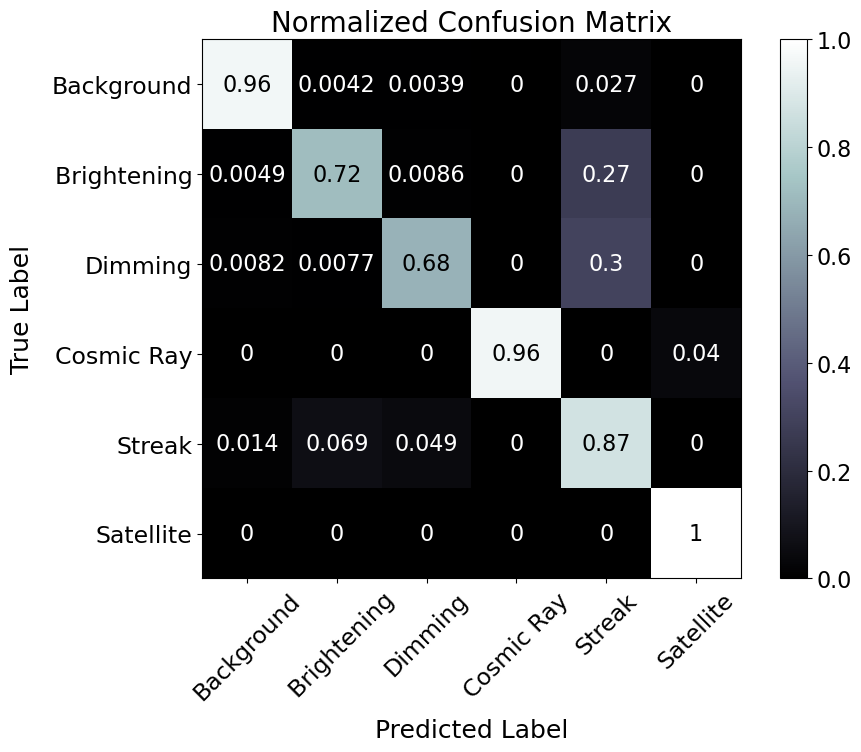

In [40]:
rff.show_confusion_matrix(save_name, sats=True, label_pred_te=None, targ_te=None, folds='average', title="Normalized Confusion Matrix", absolute=False)

loading data


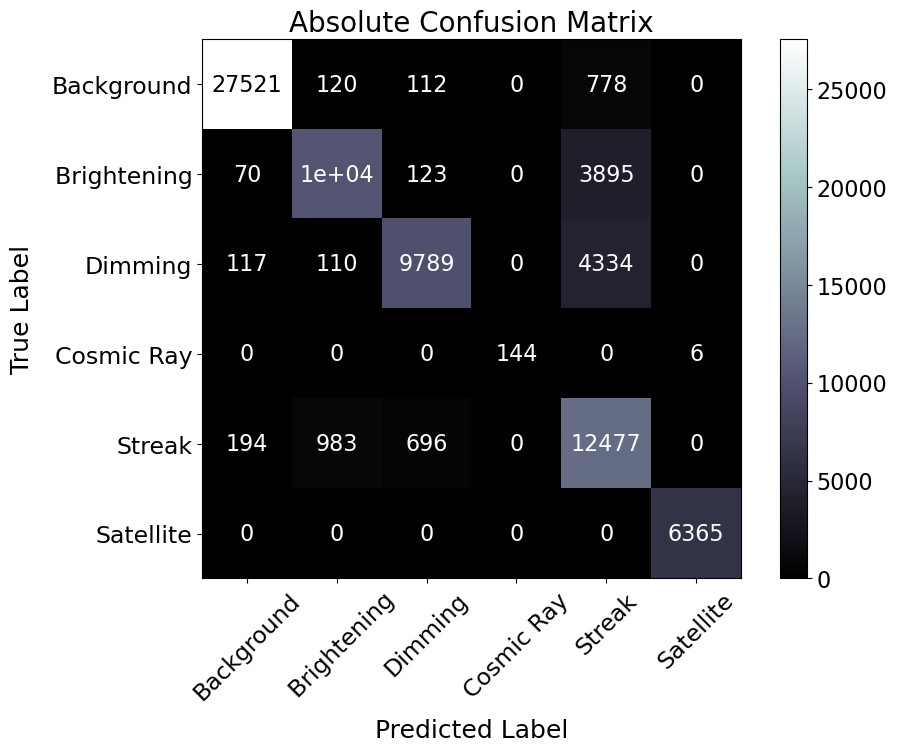

In [37]:
rff.show_confusion_matrix(save_name, sats=True, label_pred_te=None, targ_te=None, folds='average', title="Absolute Confusion Matrix", absolute=True)

In [37]:
info_te = np.load('/home/3155/saved_loss/offset_sat_newhparam_b50_allstamps_satdumbsplit_folds_info_te.npy')

In [36]:
targ_te = np.load('/home/3155/saved_loss/targ_te_offset_sat_newhparam_b50_allstamps_satdumbsplit_folds.npy')

In [38]:
our_bness_te = np.load('/home/3155/saved_loss/our_bness_te_offset_sat_newhparam_b50_allstamps_satdumbsplit.npy')

In [54]:
our_bness_te

array([0.95, 1.4 , 1.05, ..., 0.95, 0.95, 1.4 ])

In [51]:
targ_te

array([4, 2, 1, ..., 4, 0, 4])

In [20]:
mask = np.sum(([targ_te==2],[targ_te==1]), axis=0)[0]

In [21]:
mask

array([0, 1, 1, ..., 0, 0, 0])

In [69]:
info_te[mask[0].astype(bool)]

array([[ 382,    0,    4,  661,  799,    0],
       [ 476,    1,    9, 1574, 2757,    2],
       [ 301,    1,    9, 2784, 1538,   -1],
       ...,
       [ 612,    0,    3, 1233, 2128,    1],
       [  53,    0,    4, 1290, 2026,    2],
       [ 474,    1,    4,  387,  429,    0]])

In [62]:
info_te

array([[ 647,    0,    0, 2427,  331,    1],
       [ 382,    0,    4,  661,  799,    0],
       [ 476,    1,    9, 1574, 2757,    2],
       ...,
       [1099,    0,    0,  840, 1340,    0],
       [2460,    0,    0,  307,  230,  -12],
       [ 349,    0,    0, 1374, 1325,    2]])

In [86]:
info_te_copy = info_te.copy().astype(float)

In [76]:
mask[0][1]

1

In [87]:
second_index = 0
for i in range(len(info_te)):
    if mask[0][i]==1:
        info_te_copy[i][1] = our_bness_te[second_index]
        second_index+=1

In [88]:
info_te_copy

array([[ 6.470e+02,  0.000e+00,  0.000e+00,  2.427e+03,  3.310e+02,
         1.000e+00],
       [ 3.820e+02,  9.500e-01,  4.000e+00,  6.610e+02,  7.990e+02,
         0.000e+00],
       [ 4.760e+02,  1.400e+00,  9.000e+00,  1.574e+03,  2.757e+03,
         2.000e+00],
       ...,
       [ 1.099e+03,  0.000e+00,  0.000e+00,  8.400e+02,  1.340e+03,
         0.000e+00],
       [ 2.460e+03,  0.000e+00,  0.000e+00,  3.070e+02,  2.300e+02,
        -1.200e+01],
       [ 3.490e+02,  0.000e+00,  0.000e+00,  1.374e+03,  1.325e+03,
         2.000e+00]])

In [89]:
targ_te_copy = targ_te.copy

In [91]:
targ_te[0].type

AttributeError: 'numpy.int64' object has no attribute 'type'

In [94]:
subset=.1
#okay so maybe what we really want is a mask that we can apply to 
#targ and pred so that we just drop the dim ones
newmask = np.zeros(len(targ_te))
secondindex = 0
for i, targ in enumerate(targ_te):
    if targ in [1,2]:
        if our_bness_te[secondindex] >= (1 + subset):
            newmask[i]=1
        elif our_bness_te[secondindex]  <= (1 - subset):
            newmask[i]=1
        secondindex+=1
    else:
        newmask[i]=1

In [34]:
def make_mask(targ_te, our_bness_te, subset):
    newmask = np.zeros(len(targ_te))
    secondindex = 0
    for i, targ in enumerate(targ_te):
        if targ in [1,2]:
            if our_bness_te[secondindex] >= (1 + subset):
                newmask[i]=1
            elif our_bness_te[secondindex]  <= (1 - subset):
                newmask[i]=1
            secondindex+=1
        else:
            newmask[i]=1
    return newmask.astype(bool)

In [39]:
newmask = make_mask(targ_te, our_bness_te, subset=.1)

In [95]:
secondindex

28700

In [96]:
len(our_bness_te)

28700

In [9]:
np.sum(newmask)

68556.0

In [99]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [101]:
np.load("/home/3155/saved_loss/label_pred_te_"+save_name+".npy")

FileNotFoundError: [Errno 2] No such file or directory: '/home/3155/saved_loss/label_pred_te_offset_sat_newhparam_b50_allstamps_satdumbsplit_folds.npy'

In [102]:
newmask

array([1., 0., 1., ..., 1., 1., 1.])

In [11]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

loading data


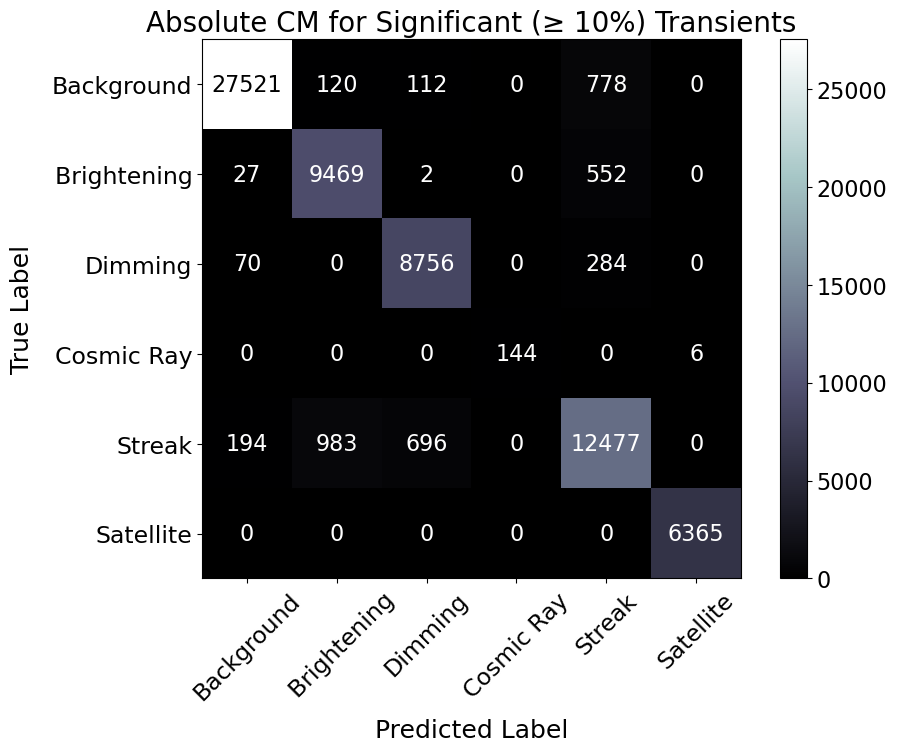

In [45]:
rff.show_confusion_matrix(save_name, sats=True, label_pred_te=None, targ_te=None, folds='average', title="Absolute CM for Significant (≥ 10%) Transients", absolute=True,mask=newmask )

loading data


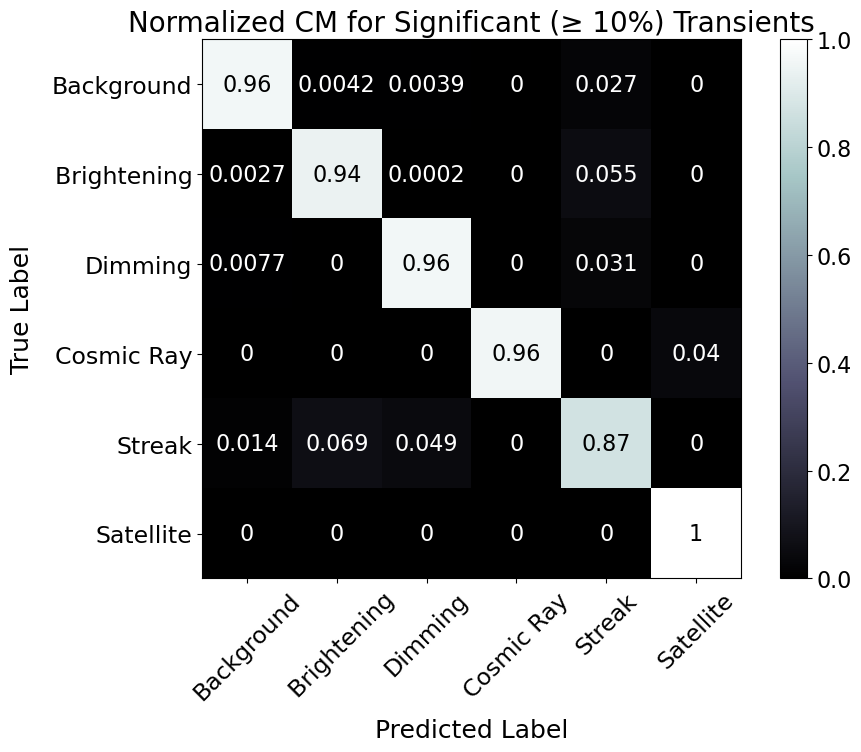

In [43]:
rff.show_confusion_matrix(save_name, sats=True, label_pred_te=None, targ_te=None, folds='average', title="Normalized CM for Significant (≥ 10%) Transients", absolute=False,mask=newmask )

In [32]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

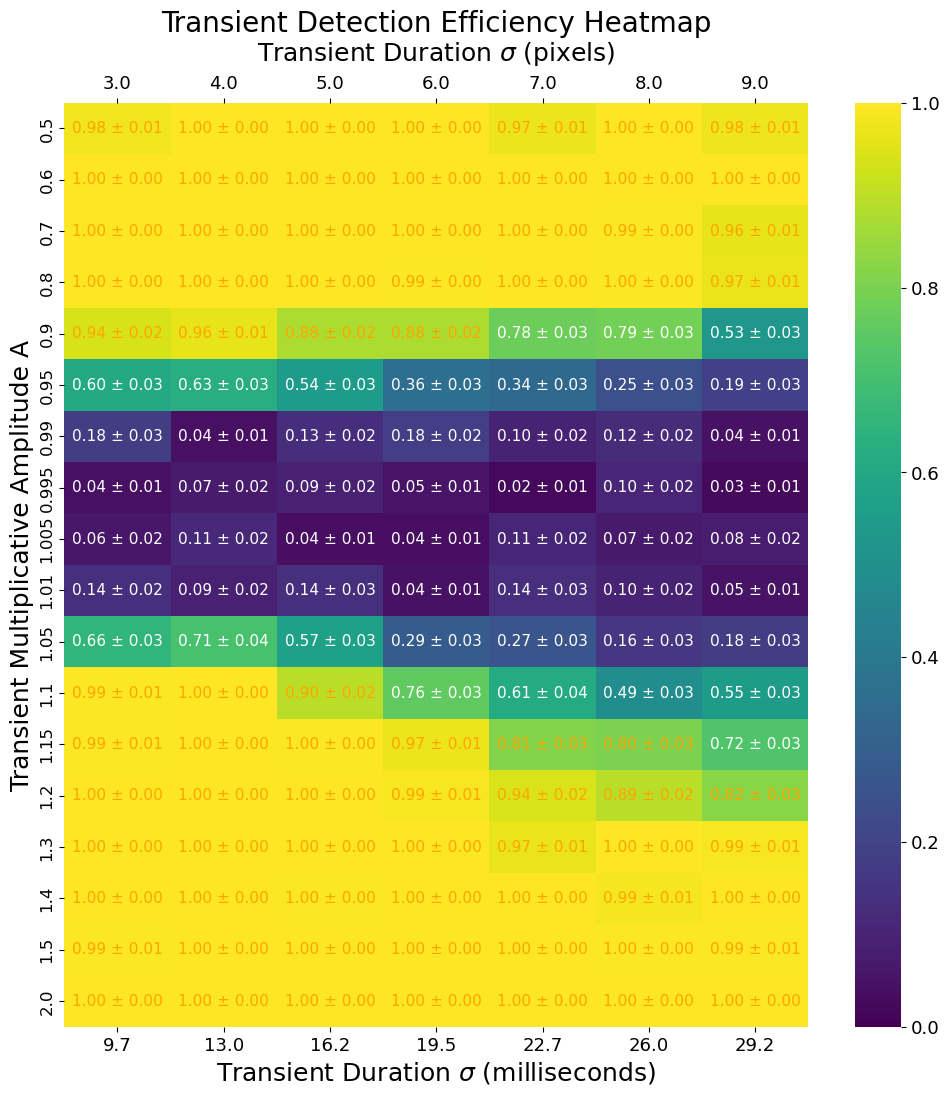

In [33]:
rff.heatmap(save_name, folds=True)

In [17]:
mask

array([0, 1, 1, ..., 0, 0, 0])

In [19]:
label_pred_te.shape

(78096, 6)

In [20]:
mask.shape

(78096,)

In [21]:
label_pred_te[mask].shape

(78096, 6)